In [1]:
#Thermompnn visualization: table and heatmap script

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap



In [2]:
#ddG heatmap data
#define your directories

df_ddG_AF3 = pd.read_csv('/projectbig/jupyternotebook/jrivera/Data/ThermoMPNN_inference_3d_wt_af3_seed_1 (1).csv')
df_pivot_AF3 = df_ddG_AF3.pivot(index='mutation', columns='position', values='ddG_pred')
df_pivot_AF3

position,0,1,2,3,4,5,6,7,8,9,...,442,443,444,445,446,447,448,449,450,451
mutation,,,,,,,,,,,,,,,,,,,,,
A,-0.107314,-0.023951,0.057642,0.000000,0.099049,-0.013893,-0.015597,0.090230,0.111864,-0.129049,...,0.096629,0.472892,0.413974,-0.220344,0.000000,0.486877,-0.062424,-0.153965,0.098090,-0.017762
C,-0.283105,-0.246871,-0.143259,-0.163440,-0.140729,-0.212964,-0.232306,-0.097846,-0.082809,-0.091589,...,0.048430,0.106144,0.000000,-0.253632,-0.507261,0.161538,-0.099050,-0.236718,-0.029591,-0.170334
D,-0.118377,0.120185,0.184051,0.117600,0.134493,0.061759,-0.022047,0.195990,0.155431,0.340514,...,0.340335,1.516515,0.712950,-0.037883,0.512211,1.235620,0.103288,-0.084429,0.482958,0.210472
E,-0.027875,0.011088,0.098114,0.167389,0.171994,0.098647,0.000000,0.254584,0.263679,0.295742,...,0.179261,1.081132,0.413033,-0.304297,0.155090,0.949110,-0.113424,-0.200090,0.369967,0.042575
F,0.029040,-0.007418,0.014418,0.136953,0.009680,-0.101140,0.078600,-0.034140,0.121319,0.111575,...,0.169574,0.041615,0.066768,0.017043,-0.464253,0.127224,0.152474,-0.019937,0.124363,-0.014020
G,-0.065748,0.069297,0.134863,0.197126,0.191980,0.107486,0.140888,0.257008,0.282360,0.000000,...,0.532778,1.155777,0.918142,0.228377,0.616185,1.092603,0.195915,0.041322,0.457379,0.213141
H,-0.024913,0.049594,0.107894,0.121739,0.048530,-0.042984,0.054175,-0.073964,0.203064,0.013077,...,0.232781,0.591130,0.348582,0.094862,-0.045087,0.683076,0.206328,0.044774,0.299909,0.082533
I,-0.040214,0.057549,0.007592,0.168853,0.034832,-0.011991,0.078852,0.125347,0.139199,0.070474,...,0.000000,-0.316106,-0.123986,0.006976,-0.531823,0.086480,0.169297,0.100532,0.000000,-0.019348
K,0.186655,0.050991,0.105358,0.180761,0.146291,0.003512,0.152889,0.075286,0.206335,-0.144968,...,0.126984,0.779453,0.583189,0.077870,0.249208,0.864203,0.121998,0.000000,0.295320,0.000000


In [7]:
#PAH variants

# Open and read your csv file
df_PAH_variants = pd.read_csv('/projectbig/jupyternotebook/jrivera/Data/20250506_PAH-variants.csv',
                              skiprows=1, index_col=0)

# Drop 'Unnamed' columns (if any)
df_PAH_variants.columns = df_PAH_variants.columns.astype(str)  # make sure they're strings
df_PAH_variants = df_PAH_variants.loc[:, ~df_PAH_variants.columns.str.contains('^Unnamed')]

# Ensure all values are numeric (0/1), convert non-numeric to 0
df_PAH_variants = df_PAH_variants.apply(pd.to_numeric, errors='coerce').fillna(0).astype(int)

# Convert columns to int if they are positions like "1.0"
df_PAH_variants.columns = df_PAH_variants.columns.astype(float).astype(int)

print(df_PAH_variants)

# Save your data as a CSV file
df_PAH_variants.to_csv ('/projectbig/jupyternotebook/jrivera/Output/PAH_variants_processed')

           1    2    3    4    5    6    7    8    9    10   ...  443  444  \
Position                                                     ...             
Aminoacid    0    0    0    0    0    0    0    0    0    0  ...    0    0   
A            0    0    0    0    0    0    0    0    0    0  ...    0    0   
C            0    0    0    0    0    0    0    0    0    0  ...    0    0   
D            0    0    0    0    0    0    0    0    0    0  ...    0    0   
E            0    0    0    0    0    0    0    0    0    0  ...    0    0   
F            0    0    0    0    0    0    0    0    0    0  ...    0    0   
G            0    0    0    0    0    0    0    0    0    0  ...    0    0   
H            0    0    0    0    0    0    0    0    0    0  ...    0    0   
I            0    0    0    0    0    0    0    0    0    0  ...    0    0   
K            0    0    0    0    0    0    0    0    0    0  ...    0    0   
L            0    0    0    0    0    0    0    0    0    0  ...

In [8]:
#PAH docking

# Open and read your CSV file
df_PAH_docking = pd.read_csv('/projectbig/jupyternotebook/jrivera/Output/Complex_PAH_6N1K_UCR102_v1_pose_1')


print(df_PAH_docking)

    Unnamed: 0 chain residue  index       x        y       z
0            0     B     ALA    322  79.892   99.288  38.198
1            1     B     ARG    252  78.127  104.442  44.851
2            2     B     ASP    253  75.420  107.120  44.788
3            3     B     ASP    282  71.055  113.057  28.179
4            4     B     CYS    265  67.749  111.218  35.466
5            5     B     GLU    280  77.491  112.233  28.576
6            6     B     GLU    286  67.707  107.715  29.503
7            7     B     GLU    330  74.038   99.740  29.797
8            8     B     HIS    264  68.689  109.588  38.765
9            9     B     HIS    285  69.913  108.088  26.421
10          10     B     HIS    290  66.628  103.219  30.354
11          11     B     ILE     25  83.401  107.337  39.478
12          12     B     LEU    248  77.192  112.209  36.819
13          13     B     LEU    249  77.208  111.058  40.432
14          14     B     LEU    255  73.597  102.299  42.356
15          15     B    

In [ ]:
#Processing of my docking data for visualization

# Create a pd data frame
df_domain = pd.DataFrame(columns=range(453)) 

# Define the PAH sequence as a list of indices from 0 to 452.
PAH = list(range(453))

# Define your AS 
AS = ('A', 'R', 'N', 'D', 'C', 'Q', 'E', 'G', 'H', 'I', 'L', 'K', 'M', 'F', 'P', 'S', 'T', 'W', 'Y', 'V')

# Make it easier to accses our colum of interest
df.rename(columns={'/projectbig/jupyternotebook/jrivera/Output/Complex_PAH_6N1K_UCR102_v1_pose_1/index': 'value'}, inplace=True)

# Change the colum/row definition of your tables and data via pivot
df.pivot(index='AS', columns='PAH', values='/projectbig/jupyternotebook/jrivera/Output/Complex_PAH_6N1K_UCR102_v1_pose_1/index')

In [9]:
#PAH domans

# Create a new panda data frame
df_domain = pd.DataFrame(columns=range(453)) 

# Define the PAH sequence as a list of indices from 0 to 452.
PAH = list(range(453))

# Define your PAH domains dictionary
PAH_domains = {
    'DHM_N_terminal': PAH[0:20],
    'RS_PAH_SAI': PAH[20:32],
    'ACT_domian': PAH[32:109],
    'linker_MCI': PAH[109:128],
    'Active_site_lid': PAH[128:151],
    'Catalytic_domain_general': PAH[151:411],
    'C_terminal_o_d': PAH[411:424],
    'Variable_hinge': PAH[424:427],
    'C_terminal_helix': PAH[427:453]
}


# Convert your dictionary data into a vector, check if there are matches in your 'indices' of your table, and change the number from 0 to 1
# We use binary heatmaps!
for domain_name, indices in PAH_domains.items(): 
    vector= np.zeros(453)
    vector [indices] = 1
    df_domain.loc[domain_name]=vector

print(df_domain)


                          0    1    2    3    4    5    6    7    8    9    \
DHM_N_terminal            1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0   
RS_PAH_SAI                0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
ACT_domian                0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
linker_MCI                0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
Active_site_lid           0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
Catalytic_domain_general  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
C_terminal_o_d            0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
Variable_hinge            0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
C_terminal_helix          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

                          ...  443  444  445  446  447  448  449  450  451  \
DHM_N_terminal            ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
RS_PAH_SAI                ...  0.0  0.0  0.0  0.0  0.0  0.0  0.

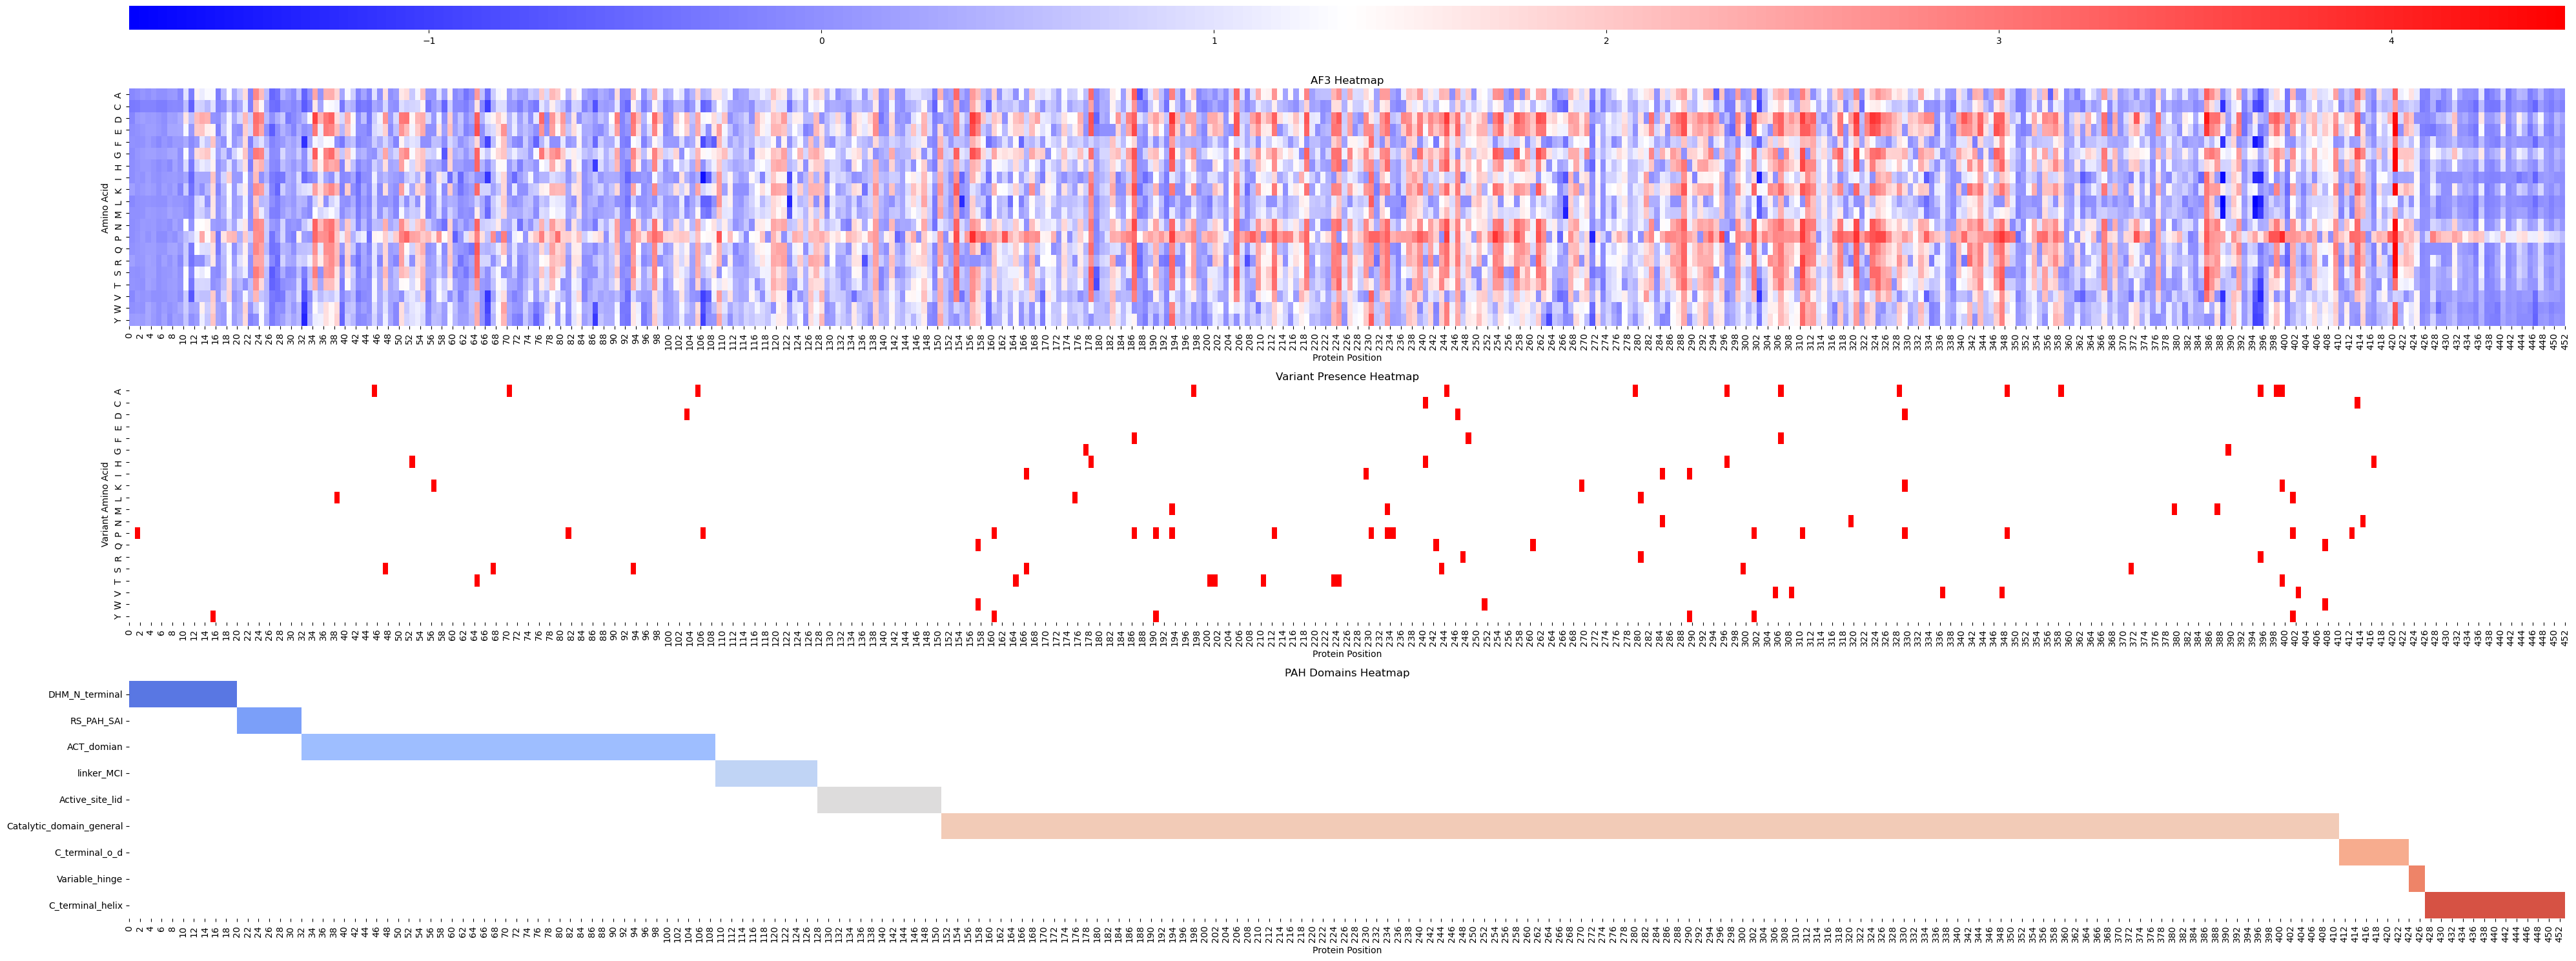

In [10]:
#Heatmap plotting

# Combine mutiple figures in one
fig, ax = plt.subplots(4, 1, figsize=(40, 15), # 4 rows, 1 column
                      gridspec_kw={'height_ratios': [0.1, 1, 1, 1]})  

# Define x-tick positions (every 2 from 0 to 452)
xticks = np.arange(0, 453, 2)

# Heatmap 1: ESM3 data
sns.heatmap(df_pivot_AF3,
            cmap='bwr',
            ax=ax[1],
            cbar_ax=ax[0],  # Assign colorbar to separate axis
            cbar_kws={'orientation': 'horizontal'})


ax[1].set_title('AF3 Heatmap')
ax[1].set_xlabel('Protein Position')
ax[1].set_ylabel('Amino Acid')
ax[1].tick_params(axis='x', rotation=90)
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)

# Heatmap 2: Variant presence heatmap
df_PAH_variants = df_PAH_variants.drop("Aminoacid", errors='ignore')
sns.heatmap(df_PAH_variants,
            cmap=["white", "red"],
            cbar= False,
            linewidths=0.000001, linecolor='gray',
            ax=ax[2])


ax[2].set_title("Variant Presence Heatmap")
ax[2].set_xlabel("Protein Position")
ax[2].set_ylabel("Variant Amino Acid")
ax[2].tick_params(axis='x', rotation=90)
ax[2].set_xticks(xticks)
ax[2].set_xticklabels(xticks)



# Heatmap 3: Domains with different colors
df_domain = pd.DataFrame(columns=range(453))
for idx, (domain_name, indices) in enumerate(PAH_domains.items(), start=1):
    row = np.zeros(453)
    row[indices] = idx  # 1, 2, 3, ... for each domain
    df_domain.loc[domain_name] = row

# Define colors: white for 0 + one color per domain
colors = ['white'] + sns.color_palette("coolwarm", len(PAH_domains)).as_hex()
cmap_domain = ListedColormap(colors)

# Plot heatmap
sns.heatmap(df_domain.astype(float),
            cmap=cmap_domain,
            cbar=False,  # Optional: show colorbar
            linewidths=0,
            linecolor='gray',
            ax=ax[3])

ax[3].set_title("PAH Domains Heatmap")
ax[3].set_xlabel("Protein Position")
ax[3].tick_params(axis='x', rotation=90)
ax[3].set_xticks(xticks)
ax[3].set_xticklabels(xticks)


plt.tight_layout()
plt.savefig('/projectbig/jupyternotebook/jrivera/Output/PAH_heatmap_AF3_final.pdf')
plt.show()
